In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import holidays
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
#checking what version of pandas has been imported
print(pd.__version__)

3.0.6


Importing all of the relevant libraries that I will be using through the rest of the project.

In [44]:
#putting the file into a table with pandas 
df = pd.read_csv("../data/demanddata_2022.csv")
#Reading the first 5 rows of the data to check it has been imported correctly
df.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,01-JAN-2022,1,21940,23275,20513,2713,6527,0,14008,0,...,-181,-4,586,320,384,-100,210,0,0,0
1,01-JAN-2022,2,22427,23489,21021,2755,6527,0,14008,0,...,-181,-4,583,320,403,-104,176,0,0,0
2,01-JAN-2022,3,21896,23672,20619,2930,6527,0,14008,0,...,-164,-4,567,320,440,-4,-205,0,0,0
3,01-JAN-2022,4,20693,23272,19615,3090,6527,0,14008,0,...,-170,-4,444,320,387,-6,-283,0,0,0
4,01-JAN-2022,5,19481,23958,18545,3161,6527,0,14008,0,...,-753,-4,-383,320,476,-561,-686,0,0,0


Here i am checking that the data I have downloaded about energy consumption in 2022 is in the correct format.

In [45]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   SETTLEMENT_DATE            17520 non-null  str  
 1   SETTLEMENT_PERIOD          17520 non-null  int64
 2   ND                         17520 non-null  int64
 3   TSD                        17520 non-null  int64
 4   ENGLAND_WALES_DEMAND       17520 non-null  int64
 5   EMBEDDED_WIND_GENERATION   17520 non-null  int64
 6   EMBEDDED_WIND_CAPACITY     17520 non-null  int64
 7   EMBEDDED_SOLAR_GENERATION  17520 non-null  int64
 8   EMBEDDED_SOLAR_CAPACITY    17520 non-null  int64
 9   NON_BM_STOR                17520 non-null  int64
 10  PUMP_STORAGE_PUMPING       17520 non-null  int64
 11  IFA_FLOW                   17520 non-null  int64
 12  IFA2_FLOW                  17520 non-null  int64
 13  BRITNED_FLOW               17520 non-null  int64
 14  MOYLE_FLOW                 17520 

In [46]:
# Converting the date column to a proper datetime format
df["date"] = pd.to_datetime(df["SETTLEMENT_DATE"], format = "%d-%b-%Y")
# Localizing the datetime to the Europe/London timezone and converting to UTC
day_start = df["date"].dt.tz_localize("Europe/London").dt.tz_convert("UTC")
# Creating a new column for the UTC timestamp
df["timestamp_utc"] = day_start + pd.to_timedelta((df["SETTLEMENT_PERIOD"] - 1) * 30, unit="min")
# Displaying the first 5 rows of the modified dataframe
df[["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "timestamp_utc", "ND"]].head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,timestamp_utc,ND
0,01-JAN-2022,1,2022-01-01 00:00:00+00:00,21940
1,01-JAN-2022,2,2022-01-01 00:30:00+00:00,22427
2,01-JAN-2022,3,2022-01-01 01:00:00+00:00,21896
3,01-JAN-2022,4,2022-01-01 01:30:00+00:00,20693
4,01-JAN-2022,5,2022-01-01 02:00:00+00:00,19481


The settlement data is text so I convert it into a real date to make it easier later on. Period 1 is the first half hour of the day.

In [71]:
#Checking there are no duplicate timestamps checking time differnece 
print("Duplicate timestamps:", df["timestamp_utc"].duplicated().sum())
print(df["timestamp_utc"].sort_values().diff().value_counts())
print(df.groupby("date").size().value_counts())

Duplicate timestamps: 0
timestamp_utc
0 days 00:30:00    17519
Name: count, dtype: int64
48    363
46      1
50      1
Name: count, dtype: int64


Here I am checking that there are no duplicate time stamps which would mean the same half hour of the same day of the same year has been logged twice. This is for the year 2022, you can see there is 1 day with 46 half hours and 1 day with 50, this is due to when the clocks go back and when the clocks go forward. 

In [48]:
files = [
    "../data/demanddata_2022.csv",
    "../data/demanddata_2023.csv",
    "../data/demanddata_2024.csv",
]

raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
raw.shape

(52608, 22)

Compressing the three years of files together.

In [49]:
#Converting the date into a format python can do date maths on and putting it into a new column.
raw["date"] = pd.to_datetime(raw["SETTLEMENT_DATE"], format="mixed", dayfirst=True)
#Labels midnight of the day in UTC, so period 1 is 00:00-00:30, period 2 is 00:30-01:00, etc.
day_start = raw["date"].dt.tz_localize("Europe/London").dt.tz_convert("UTC")
#Each row says which of the day’s half-hour slots it is (period 1 is the first). Period 1 starts at midnight, so we subtract 1 multiply by 30 and add that many minutes to the day’s start. Period 5 becomes midnight + 120 minutes, which is 02:00
raw["timestamp_utc"] = day_start + pd.to_timedelta((raw["SETTLEMENT_PERIOD"] - 1) * 30, unit="min")

demand = (
    raw[["timestamp_utc", "date", "SETTLEMENT_PERIOD", "ND"]]
    #puts rows in time order
    .sort_values("timestamp_utc")
    .set_index("timestamp_utc")
)

demand.head()


,date,SETTLEMENT_PERIOD,ND
timestamp_utc,,,
2022-01-01 00:00:00+00:00,2022-01-01,1,21940
2022-01-01 00:30:00+00:00,2022-01-01,2,22427
2022-01-01 01:00:00+00:00,2022-01-01,3,21896
2022-01-01 01:30:00+00:00,2022-01-01,4,20693
2022-01-01 02:00:00+00:00,2022-01-01,5,19481


The files for 2022, 2023 and 2024 have different data formats so letting pandas infer the format row by row.

In [50]:
print("Rows:", len(demand))
print("Duplicate timestamps:", demand.index.duplicated().sum())
print()
print(demand.index.to_series().diff().value_counts())
print()
print(demand.groupby("date").size().value_counts())

Rows: 52608
Duplicate timestamps: 0

timestamp_utc
0 days 00:30:00    52607
Name: count, dtype: int64

48    1090
46       3
50       3
Name: count, dtype: int64


Checking information about the dataframe demand. We can see it is correct as there are 3 days with 46 time slots 3 with 50 and 1090 with 48.

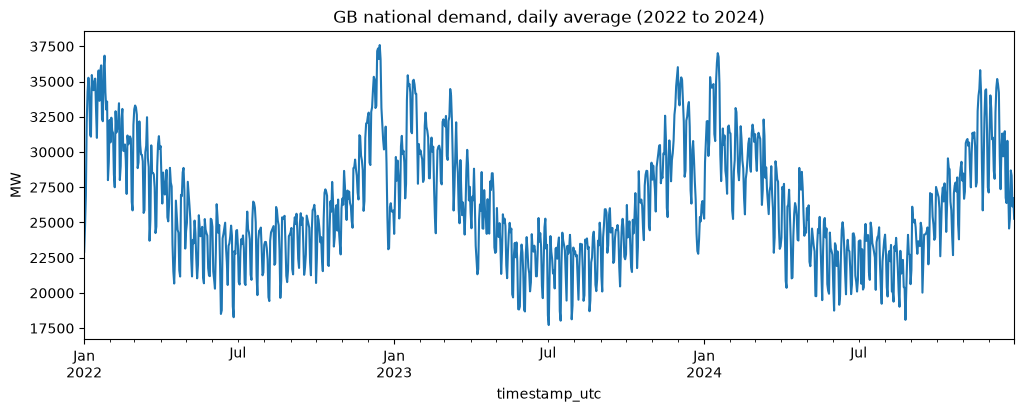

In [51]:

daily = demand["ND"].resample("D").mean()
#Using matplotlib to plot the daily demand avergae across the 3 years of data.
daily.plot(figsize=(12, 4))
plt.title("GB national demand, daily average (2022 to 2024)")
plt.ylabel("MW")
plt.show()

From 2022 to 2024 demand is highest during the colder winter months of the year then drops as the summer months approach.

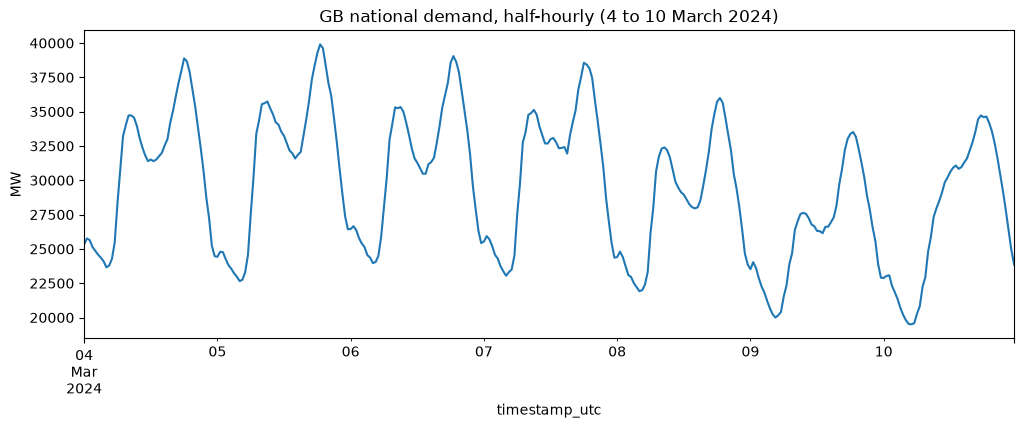

In [52]:
week = demand.loc["2024-03-04":"2024-03-10", "ND"]
#Using matplotlib to plot the half hourly demand for a week in march 2024
week.plot(figsize=(12, 4))
plt.title("GB national demand, half-hourly (4 to 10 March 2024)")
plt.ylabel("MW")
plt.show()

Demand seems to be the same day to day through the week.

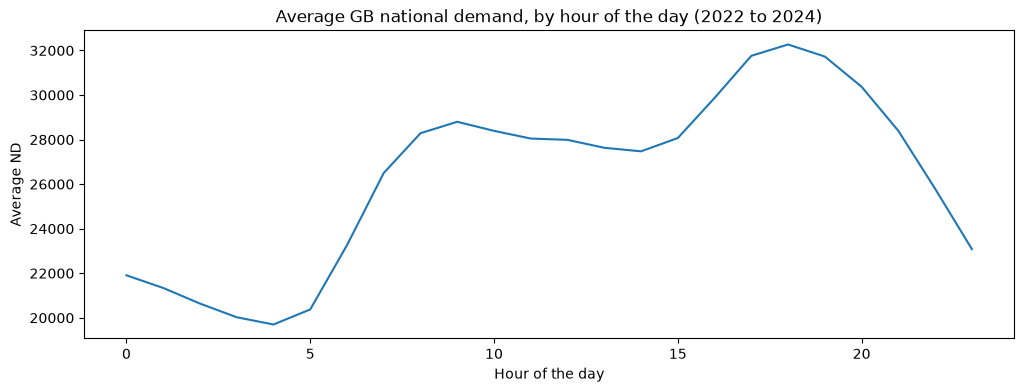

In [53]:
hourly = (demand["ND"].groupby(demand.index.tz_convert("Europe/London").hour).mean()
)
#Using matplotlib to plot the average demadn by hour of the day across the 3 years of data.
hourly.plot(figsize=(12, 4))
plt.title("Average GB national demand, by hour of the day (2022 to 2024)")
plt.ylabel("Average ND")
plt.xlabel("Hour of the day")
plt.show()

Demand is hugher during the evenings.

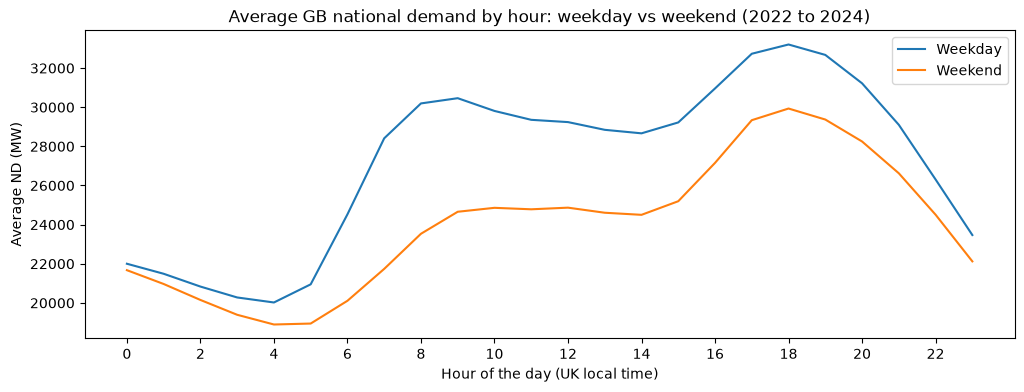

In [54]:
#Converting to local time to check if it is a weekend or not
local = demand.index.tz_convert("Europe/London")
#Weekdays are days 0-4 while weekends are days 5-6, we are telling python this here.
is_weekend = local.dayofweek >= 5
#Creating a new table that shows the average demand by hour of the day and whether it is a weekday or weekend.
by_daytype = (
    demand["ND"]
    .groupby([local.hour, is_weekend])
    .mean()
    .unstack()
)

by_daytype.columns = ["Weekday", "Weekend"]

by_daytype.plot(figsize=(12, 4))
plt.title("Average GB national demand by hour: weekday vs weekend (2022 to 2024)")
plt.xlabel("Hour of the day (UK local time)")
plt.ylabel("Average ND (MW)")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.show()


Demand is higher on weekdays compared to weekends, this could be due to people being out of the house at weekends.

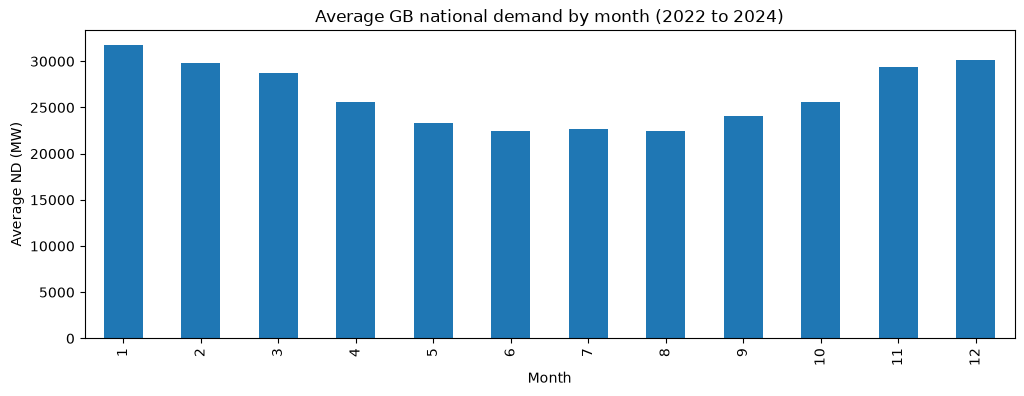

In [72]:

#Grouping the data by month and calculating the average demand for each month
by_month = demand["ND"].groupby([local.month]).mean()
by_month.plot(kind = "bar", figsize=(12, 4))
plt.title("Average GB national demand by month (2022 to 2024)")
plt.xlabel("Month")
plt.ylabel("Average ND (MW)")
plt.show()

Demand Peaks around December - January time and slows mid year in the summer, this is probably due to warmer weather in the summer months.

In [56]:

features = pd.DataFrame(index=demand.index)
features["half_hour"] = local.hour * 2 + local.minute // 30
features["dayofweek"] = local.dayofweek
features["month"] = local.month

features.head()

,half_hour,dayofweek,month
timestamp_utc,,,
2022-01-01 00:00:00+00:00,0,5,1
2022-01-01 00:30:00+00:00,1,5,1
2022-01-01 01:00:00+00:00,2,5,1
2022-01-01 01:30:00+00:00,3,5,1
2022-01-01 02:00:00+00:00,4,5,1


Creates table documenting every day, 2022 through to 2024 and splits it into half hours. 

In [57]:
uk_holidays = holidays.country_holidays("GB", subdiv="ENG", years=[2022, 2023, 2024])

features["bank_holiday"] = (
    pd.Series(local.date, index=demand.index)
    .isin(list(uk_holidays.keys()))
    .astype(int)
)

features.head()

,half_hour,dayofweek,month,bank_holiday
timestamp_utc,,,,
2022-01-01 00:00:00+00:00,0,5,1,1
2022-01-01 00:30:00+00:00,1,5,1,1
2022-01-01 01:00:00+00:00,2,5,1,1
2022-01-01 01:30:00+00:00,3,5,1,1
2022-01-01 02:00:00+00:00,4,5,1,1


Imports a library that contains all of the bank holiday dates of the uk through the last few years, then marks each day which is a bank holiday with a 1.

In [58]:
features["Yesterday"] = demand["ND"].shift(48)
features["Last_week"] = demand["ND"].shift(48 * 7)
features.describe()

,half_hour,dayofweek,month,bank_holiday,Yesterday,Last_week
count,52608.000000,52608.000000,52608.000000,52608.000000,52560.000000,52272.000000
mean,23.500000,3.000000,6.522696,0.027372,26321.202702,26319.551098
std,13.853531,2.002299,3.449014,0.163167,6035.039356,6040.334925
min,0.000000,0.000000,1.000000,0.000000,13601.000000,13601.000000
25%,11.750000,1.000000,4.000000,0.000000,21606.000000,21602.000000
50%,23.500000,3.000000,7.000000,0.000000,25520.500000,25516.000000
75%,35.250000,5.000000,10.000000,0.000000,30120.250000,30114.000000
max,47.000000,6.000000,12.000000,1.000000,46147.000000,46147.000000


Adds two more columns to the table that has been created, one column shows the energy used for this time last week and the other column shows the energy used for the same time yesterday. The head shows these columns to be NaN because we have not downloaded data from 2021 only 2022 - 2024.

In [59]:

print(features.columns.tolist())
print(features.isna().sum())

['half_hour', 'dayofweek', 'month', 'bank_holiday', 'Yesterday', 'Last_week']
half_hour         0
dayofweek         0
month             0
bank_holiday      0
Yesterday        48
Last_week       336
dtype: int64


Checks that the table we have created is correct. 

In [60]:
data = features.join(demand["ND"]).dropna()





Creates a new table called data which adds ND as a column 

In [61]:
train = data.loc["2022-01-01 00:00:00":"2023-12-31 23:59:59"]
test = data.loc["2024-01-01 00:00:00":"2024-12-31 23:59:59"]

x_train = train.drop(columns=["ND"])
y_train = train["ND"]
x_test = test.drop(columns=["ND"])
y_test = test["ND"] 

Here I have created 4 objects, the x objects hold the 6 columns from data we collected earlier and the y objects hold the ND. I have split these objects between the train data for years 2022, 2023 to the test data for years 2024. What I am doing here is preparing the data for years 2022, 2023 to help predict what the future ND will be and I will use 2024 as a benchmark to see how accurate these tests are.

In [62]:
baseline_prediction = x_test["Last_week"]
baseline_MAE = sk.metrics.mean_absolute_error(y_test, baseline_prediction)
baseline_RMSE = sk.metrics.root_mean_squared_error(y_test, baseline_prediction)
print(baseline_MAE)
print(baseline_RMSE)
print(y_test.mean())
MAE_percentage = (baseline_MAE /y_test.mean() * 100).round(2)
print("The errors in the dataset are about", MAE_percentage,"% of the average demand")

2027.9001024590164
2686.538444696779
26286.762978142076
The errors in the dataset are about 7.71 % of the average demand



Before building any models, I need a simple benchmark to beat. The baseline predicts that demand at any half-hour will equal demand at the same half-hour one week earlier (the `Last_week` feature). It involves no training, so it shows what a trivial forecast achieves on the 2024 test set

In [63]:
#List of three columns that are categorical and need to be converted into dummy variables for the linear regression model.
cat_cols = ["half_hour", "dayofweek", "month"]

#A linear model gives each column one weight so this fixes that by converting the categorical columns into dummy variables. This means that each category gets its own column with a 1 or 0 to indicate whether it is that category or not. This allows the linear model to give each category its own weight.
X_train_lin = pd.get_dummies(x_train, columns=cat_cols, dtype=float)
X_test_lin = pd.get_dummies(x_test, columns=cat_cols, dtype=float)
#The model learns one weight per column, so the test table must have exactly the same columns in exactly the same order as the training table. If a category appeared in only one of the two sets, the columns would differ and the model would fail, or worse, quietly mix columns up.
X_test_lin = X_test_lin.reindex(columns=X_train_lin.columns, fill_value=0)
print("Columns match:", X_train_lin.columns.equals(X_test_lin.columns))

#Creates and empty linear regression model
lin_model = LinearRegression()
#Model looks at the training data and the demand that followed and finds a weight for each column that best explains the demand
lin_model.fit(X_train_lin, y_train)
#This applies the weights to the test data to predict the demand that will follow
lin_pred = lin_model.predict(X_test_lin)
#Comparing the predicted demand to the actual demand to see how well the model did
lin_mae = mean_absolute_error(y_test, lin_pred)
#Does the same comparison but using root mean squared error instead of mean absolute error. This is more sensitive to large errors and is a better measure of how well the model did.
lin_rmse = root_mean_squared_error(y_test, lin_pred)

print(f"Baseline MAE:           {baseline_MAE:,.0f} MW")
print(f"Linear regression MAE:  {lin_mae:,.0f} MW")
print(f"Baseline RMSE:          {baseline_RMSE:,.0f} MW")
print(f"Linear regression RMSE: {lin_rmse:,.0f} MW")

Columns match: True
Baseline MAE:           2,028 MW
Linear regression MAE:  1,399 MW
Baseline RMSE:          2,687 MW
Linear regression RMSE: 1,827 MW


Model 1: Linear Regression
This first model is linear regression it learns one weight for each input column and combines them into a forecast 
The model was fitted on the training data which is years 2022 and 2023 and scored on year 2024


In [64]:
#Creating an empty gradient boosting model.
gb_model = HistGradientBoostingRegressor(
    max_iter=300,#number of trees to build, more trees means a more complex model that can fit the training data better.
    early_stopping=False,
    random_state=0,
)
#The model looks at the training data and the demand that followed and finds a weight for each column that best explains the demand 
gb_model.fit(x_train, y_train)
#This feeds the 2024 inputs through all 300 trees and adds up their contributions to produce a forecast for every half-hour
gb_pred = gb_model.predict(x_test)
#Compares forecasts with the real 1014 demand
gb_mae = mean_absolute_error(y_test, gb_pred)
#The same comparison, but each error is squared before averaging and the square root taken at the end, so big misses count for more.
gb_rmse = root_mean_squared_error(y_test, gb_pred)

print(f"Baseline MAE:           {baseline_MAE:,.0f} MW")
print(f"Linear regression MAE:  {lin_mae:,.0f} MW")
print(f"Gradient boosting MAE:  {gb_mae:,.0f} MW")
print()
print(f"Baseline RMSE:          {baseline_RMSE:,.0f} MW")
print(f"Linear regression RMSE: {lin_rmse:,.0f} MW")
print(f"Gradient boosting RMSE: {gb_rmse:,.0f} MW")

Baseline MAE:           2,028 MW
Linear regression MAE:  1,399 MW
Gradient boosting MAE:  1,249 MW

Baseline RMSE:          2,687 MW
Linear regression RMSE: 1,827 MW
Gradient boosting RMSE: 1,676 MW


This model is gradient boosting, it builds small decision trees that each correct the errors of the previous ones so that it can capture interactions that a linear model cannot. For example one of these interactions may be the evening peak that is different in the winter compared to the summer.
I switched off early stoppage because scikitlearn default holds back a random slice of the training data which would leak future information in a time series.

In [65]:
results = pd.DataFrame(
    {
        "MAE (MW)": [baseline_MAE, lin_mae, gb_mae],
        "RMSE (MW)": [baseline_RMSE, lin_rmse, gb_rmse],
    },
    index=["Baseline (same time last week)", "Linear regression", "Gradient boosting"],
)

results["MAE improvement (%)"] = (1 - results["MAE (MW)"] / baseline_MAE) * 100
results["RMSE improvement (%)"] = (1 - results["RMSE (MW)"] / baseline_RMSE) * 100

results.round(1)
results.describe()

,MAE (MW),RMSE (MW),MAE improvement (%),RMSE improvement (%)
count,3.000000,3.000000,3.000000,3.000000
mean,1558.674970,2063.203085,23.138474,23.202175
std,413.296514,545.065175,20.380516,20.288754
min,1248.664526,1676.131051,0.000000,0.000000
25%,1324.062403,1751.535405,15.494842,15.998258
50%,1399.460280,1826.939760,30.989683,31.996515
75%,1713.680191,2256.739102,34.707711,34.803263
max,2027.900102,2686.538445,38.425738,37.610011


Results Summary
All three approaches were scored on the same held out 2024 test set. The improvement columns show how much each model reduces error compared with the same time last week baseline.

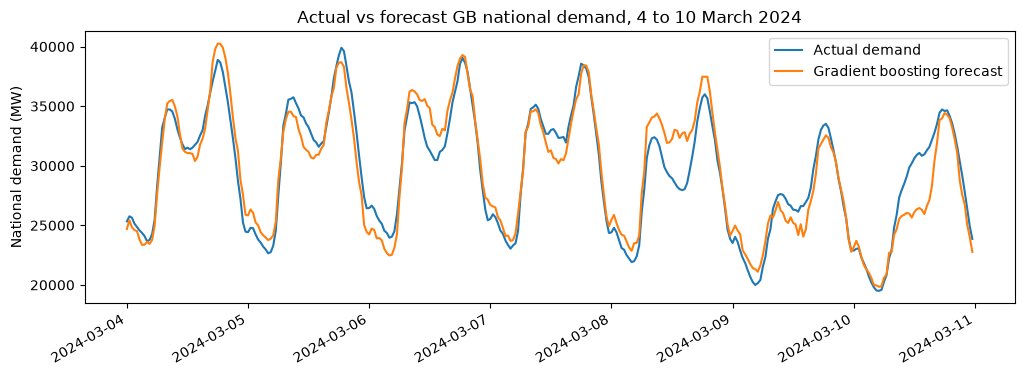

In [66]:
gb_series = pd.Series(gb_pred, index=y_test.index)

week_actual = y_test.loc["2024-03-04":"2024-03-10"]
week_pred = gb_series.loc["2024-03-04":"2024-03-10"]

plt.figure(figsize=(12, 4))
plt.plot(week_actual.index, week_actual, label="Actual demand")
plt.plot(week_pred.index, week_pred, label="Gradient boosting forecast")
plt.title("Actual vs forecast GB national demand, 4 to 10 March 2024")
plt.ylabel("National demand (MW)")
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

The chart shows one week of the 2024 test set, with actual demand and the gradient boosting forecast on the same axes

Rows per group:
bank_holiday
Normal day      17184
Bank holiday      384
Name: count, dtype: int64

Mean absolute error (MW):
              Baseline  Gradient boosting
bank_holiday                             
Normal day      1989.0             1244.0
Bank holiday    3761.0             1457.0


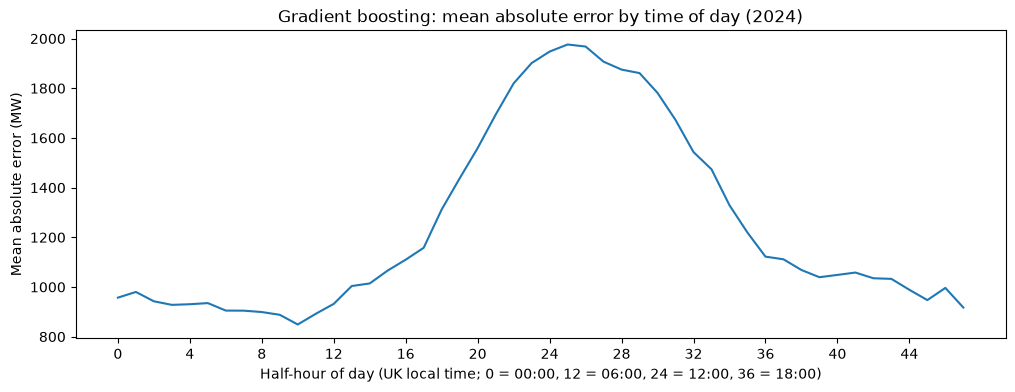

In [74]:
#Creattes a new table which will show us how far off the predicitons were compared to what actually happened in 2024.
errors = pd.DataFrame({
    "Baseline": (y_test - x_test["Last_week"]).abs(), #The last week column, subtracting it from the real demand gives the miss for each half hour,.abs drops the sign.
    "Gradient boosting": (y_test - gb_pred).abs(),#Same calculation for Gradient boosting, subtracting the forecast from the real demand and taking the absolute value to get the miss for each half hour.
})
#
by_holiday = (
    errors.groupby(x_test["bank_holiday"])#This sorts the rows into two groups using the bank holiday flag: rows where it’s 0 and rows where it’s 1.
    .mean()
    .rename(index={0: "Normal day", 1: "Bank holiday"})
)

print("Rows per group:")
print(x_test["bank_holiday"].map({0: "Normal day", 1: "Bank holiday"}).value_counts())
print()
print("Mean absolute error (MW):")
print(by_holiday.round(0))
#Takes the gradient boosting errors and groups them by the half hour of the day, then takes the mean of each group to see how the model performs at different times of the day.
by_half_hour = errors["Gradient boosting"].groupby(x_test["half_hour"]).mean()
#Creates a line plot of the mean absolute error by half hour of the day, with appropriate labels and title.
by_half_hour.plot(figsize=(12, 4))
plt.title("Gradient boosting: mean absolute error by time of day (2024)")
plt.xlabel("Half-hour of day (UK local time; 0 = 00:00, 12 = 06:00, 24 = 12:00, 36 = 18:00)")
plt.ylabel("Mean absolute error (MW)")
plt.xticks(range(0, 48, 4))
plt.savefig("../forecast_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

Overall scores hide where a model goes wrong, so I split the 2024 errors in two ways. Each error is the absolute difference between forecast and actual demand, in MW. Note that 2024 contains only 8 bank holiday dates (384 half-hours), so the holiday figures come from a small sample.
